<a href="https://colab.research.google.com/github/freddyjosephthanikkal/Deep_Learning/blob/main/RGB_image_classifier_Handbag_and_Shoes_Without_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
!!pip install -q git+https://github.com/keras-team/keras-hub.git
!!pip install -q --upgrade keras

[]

* ! -> execute a shell command
* !! -> execute a shell command and capture its output as a list of lines
* package manager / library
* -q -> install quietly -> no notifications
* Upgrade to Keras 3

In [29]:
import os
import json
import math
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import losses
from keras import ops
from keras import optimizers
from keras.optimizers import schedules
from keras import metrics
from keras.applications.imagenet_utils import decode_predictions
import keras_hub

import tensorflow as tf
import tensorflow_datasets as tfds

* os -> helps python to interact with th operating system -> the files in the computer
* json -> JavaScript Object Notation -> stores structured information
* math -> standard math library
* losses -> calculate the model loss
* ops -> operation -> mathamatical and tensor operations
* optimizers -> update the weights and biases -> like sgd, adam, RMSprop
* schedules -> uses the optimizer's configured learning rate throughout training unless changed.
* metrics -> show the metrics data like precision, accuracy, etc
* decode_predictions -> convert the numerical predictions to human readable labels.
* keras_hub -> pretrained neural network components and architectures.
* tensorflow_datasets -> It provides features such as:
      - Downloading and preparing datasets.
      - Splitting datasets into training and testing portions.
      - Loading data in batches.
      - Shuffling examples.
      - Building input pipelines

In [30]:
from tensorflow import keras
from keras.layers import Dropout, Dense, GlobalAveragePooling1D, Flatten
import keras_hub
from keras import layers
from keras.layers import Lambda
import pandas as pd
import matplotlib.pyplot as plt
keras.utils.set_random_seed(42)

* Dropout -> technique to reduce overfitting -> it randomly disables a fraction of outputs during training.
* Dense -> fully connected layers
* GlobalAveragePooling -> takes input matrix, averages its rows -> so a matrix of size 4*3 becomes 1*3
* Flatten -> Rearrange the matrix to a long vector -> (6,6,32) -> (1152)
* Keras_hub -> provides pretrained models and components -> Instead of training a CNN from scratch, start with a model that has already learned useful visual features from a large dataset -> Transfer Learning
* Layers -> Imports keras layers -> eg -> layers.dense(256) -> same as from keras.layers import Dropout, Dense, GlobalAveragePooling1D, Flatten
* Lambda -> Turn a custom mathematical operation to a keras layer.


In [31]:
!wget -q -P ./ https://www.dropbox.com/s/w07liww46kgxo1m/handbags-shoes.zip
!unzip -qq handbags-shoes.zip

replace handbags-shoes/.DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


* ! ->	Runs a shell command from a Colab notebook cell.
* wget ->	Downloads a file from a URL.
* -q ->	Quiet mode; suppresses download progress and most messages.
* -P ./ ->	Saves the downloaded file in the current directory.
* URL	-> The location of the ZIP file.
* unzip ->	Extracts ZIP archives.
* -qq	-> Extra-quiet mode; suppresses extraction messages.
* handbags-shoes.zip	-> The archive to extract.

In [32]:
import os, shutil, pathlib
base_dir = pathlib.Path("/content/handbags-shoes")

* shutil -> shell utility -> high level file operations
* pathlib -> working with file paths
* base_dir -> the extracted content path is stored in a variable named base_dir

In [33]:
for category in ('handbags', 'shoes'):
  fnames = os.listdir(base_dir/category)

  dir = base_dir /'train' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[:50]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

  dir = base_dir /'validation' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[50:75]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

  dir = base_dir /'test' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[75:]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

* for loop -> runs twice -> create directory for shoes and handbag.
* 2 folders -> containing separate training, validation and test folders
* fnames[] -> fixed split based on the order returned by os.listdir()
           -> Does not randomly shuffle the images before split!
* exist_ok=True -> Check if the directories already exixts

In [34]:
train_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'train',
    image_size=(224, 224),
    batch_size=32)

validation_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'validation',
    image_size=(224, 224),
    batch_size=32)

test_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'test',
    image_size=(224, 224),
    batch_size=32)


Found 96 files belonging to 2 classes.
Found 49 files belonging to 2 classes.
Found 40 files belonging to 2 classes.


* creating datasets from the previously arranged folders for training, testing and validation.
* all images are resized to 244*244 pixels.
* keras also makes batches of 32 images and corresponding labels.
* Convert the images to tensors.

In [35]:
for images, _ in train_dataset.take(1):
    print(images[0].shape)

(224, 224, 3)


* Each image is 244*244 and has RGB channels -> so (244,244,3)
* for loop needs the next line to start with a tab space!

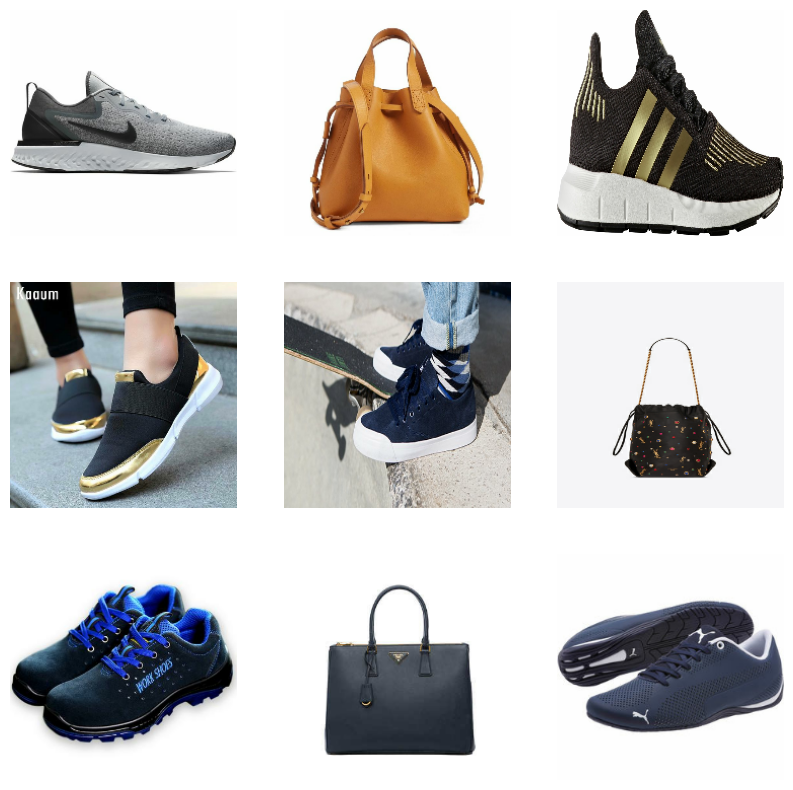

In [36]:
plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")

* Display 9 sample image from the training dataset in a 3*3 grid
* 10*10 inch canvas
* for images, _ in train_dataset.take(1): takes the first batch in the train_dataset
* it has both images and labels -> we use a "_" to exclude using the labels.
* (3, 3, i + 1) -> (rows, columns, position)
* imshow -> can display the numpy arrays as images!
* .astype("uint8") -> convert to unsigned int 8 bit

In [37]:
input = keras.Input(shape=(224,224,3))

# we normalize "inside" the model with a Rescaling layer
# so that we don't have to remember to do it every time
# we need to use the model to make a prediction
h = keras.layers.Rescaling(1./255)(input)
# This layer divides every pixel by 255


# first convolutional block
h = keras.layers.Conv2D(32,                    # the number of filters
                        kernel_size=(2, 2),    # the shape of each filter
                        activation="relu",
                        name="Conv_1")(h)
h = keras.layers.MaxPool2D()(h)


# second convolutional block
h = keras.layers.Conv2D(32,                    # the number of filters
                        kernel_size=(2, 2),    # the shape of each filter
                        activation="relu",
                        name="Conv_2")(h)
h = keras.layers.MaxPool2D()(h)

# flatten layer
h = keras.layers.Flatten()(h)

# output layer
output = keras.layers.Dense(1, activation="sigmoid")(h)

model = keras.Model(input, output)

In [38]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 223, 223, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 110, 110, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 55, 55, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 96800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        96,801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,345 (395.88 KB)

 Trainable params: 101,345 (395.88 KB)

 Non-trainable params: 0 (0.00 B)

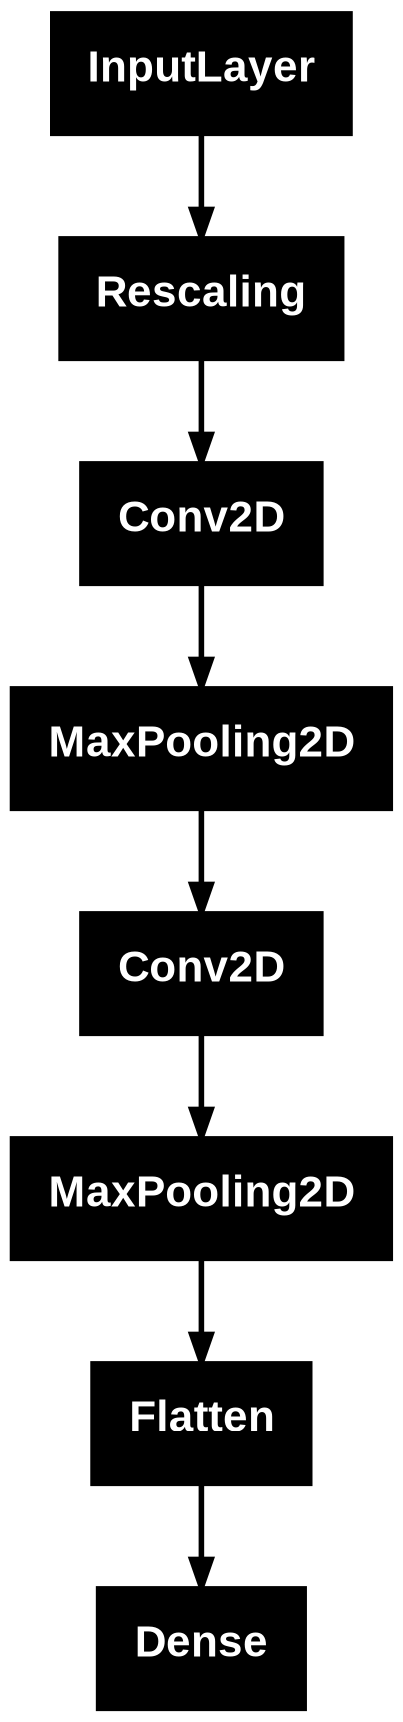

In [39]:
keras.utils.plot_model(model)

In [40]:
model.compile(loss='binary_crossentropy',
             optimizer='adam',
             metrics=['accuracy'])

In [41]:
history = model.fit(train_dataset,
                    epochs=20,
                    validation_data=validation_dataset)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.4271 - loss: 2.0006 - val_accuracy: 0.4898 - val_loss: 0.8413
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.5104 - loss: 1.2363 - val_accuracy: 0.4898 - val_loss: 1.1247
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 325ms/step - accuracy: 0.6667 - loss: 0.7401 - val_accuracy: 0.5714 - val_loss: 0.6150
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 329ms/step - accuracy: 0.5312 - loss: 0.6947 - val_accuracy: 0.5102 - val_loss: 0.7036
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 330ms/step - accuracy: 0.5938 - loss: 0.6232 - val_accuracy: 0.7755 - val_loss: 0.5467
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 323ms/step - accuracy: 0.7500 - loss: 0.4942 - val_accuracy: 0.5306 - val_loss: 0.5883
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 351ms/step - accuracy: 0.8750 - loss: 0.4141 - val_accuracy: 0.8980 - val_loss: 0.4521
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 433ms/step - accuracy: 0.9167 - loss: 0.3556 - val_accuracy: 0.8980 - val_loss: 0.3974
Epoch 9/2

In [42]:
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()

def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

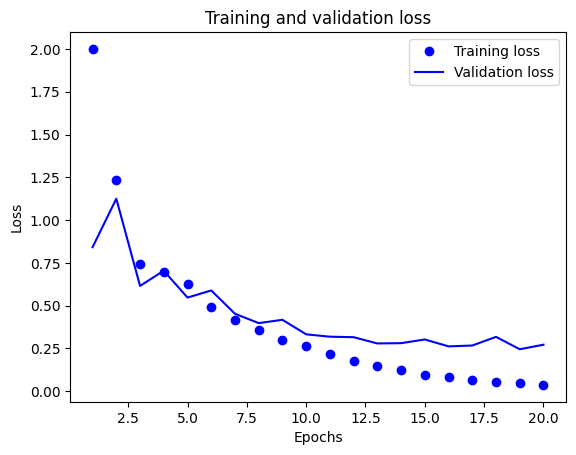

In [43]:
plot_loss_curves(history)

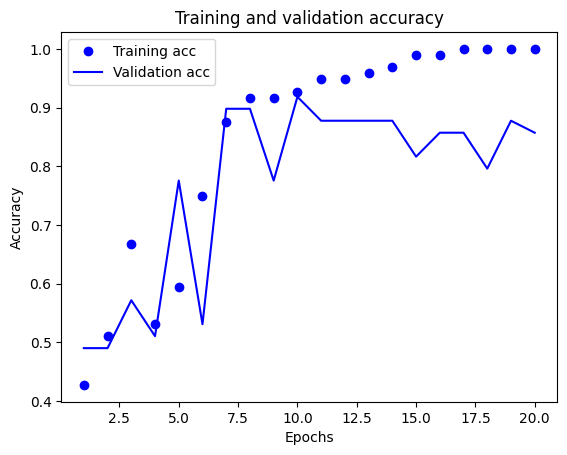

In [44]:
plot_acc_curves(history)

In [45]:
model.evaluate(test_dataset)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 450ms/step - accuracy: 0.8750 - loss: 0.3084


[0.30840808153152466, 0.875]